### Credit Card Fraud Detection — Playground S6E11

**Goal:** predict `is_fraud` while minimizing business cost (missed fraud + false-alarm friction).

**Metric:** PR-AUC (honest for imbalance) + recall@fixed-FPR (production) + business cost curve.

#### Loading the dataset

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

# Project paths
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

# Configuration
TARGET = "is_fraud"
ID_COL = "id"

# Load data
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")

print("Train:", train.shape)
print("Test:", test.shape)

Train: (699960, 26)
Test: (299984, 25)


#### Understanding the dataset

In [2]:
# First five observations
display(train.head())

# Random observations
display(train.sample(5, random_state=42))

# Dataset information
train.info()

# Descriptive statistics
display(train.describe().T)

# Categorical variables
display(train.describe(include="object").T)

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
451125,451125,31.47,8.51,3,18.73,55,56,699.40,0,0.0,0,1,19.5,0,Online Retail,Mastercard,OTP,Online,POS Terminal,False,False,False,False,False,False,0.0
370124,370124,10.07,4.65,7,1.96,48,24,677.78,0,24.6,4,6,24.7,0,Streaming,Visa,PIN,Online,Android Phone,False,False,False,False,False,False,0.0
504395,504395,37.79,4.16,4,16.86,54,37,764.18,0,0.0,17,1,63.5,0,Gift Cards,Mastercard,OTP,In-App,iPhone,False,False,False,False,False,False,0.0
103461,103461,50.59,6.21,2,2.57,53,53,921.48,0,15.0,5,5,20.9,0,Utilities,Mastercard,3D Secure,POS,POS Terminal,False,False,False,False,False,False,0.0
670980,670980,22.74,7.52,1,0.89,50,49,3022.38,0,0.0,19,4,38.3,0,Healthcare,Visa,No Authentication,Contactless,iPhone,False,False,False,False,False,False,0.0


<class 'pandas.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week                   699960 non-null  int64  
 12  merchant_risk_score           699960 non-null  float64


,count,mean,std,min,25%,50%,75%,max
id,699960.0,349979.500000,202061.191549,0.00,174989.75,349979.50,524969.25,699959.00
amount_usd,699960.0,79.893068,205.173538,1.00,15.81,27.25,43.11,6872.69
hours_since_last_txn,699960.0,6.633734,6.290133,0.01,2.11,4.73,9.19,51.98
txn_count_last_24h,699960.0,2.984092,1.498998,0.00,2.00,3.00,4.00,11.00
distance_from_home_km,699960.0,13.587575,11.617325,0.00,4.43,10.22,19.75,57.93
card_age_months,699960.0,46.862982,5.579190,25.00,43.00,47.00,51.00,73.00
customer_age,699960.0,51.430286,17.899150,18.00,38.00,52.00,66.00,81.00
account_balance_usd,699960.0,2064.998070,3400.132922,58.25,834.12,1382.74,2517.02,99701.39
cvv_retry_count,699960.0,0.085472,0.289524,0.00,0.00,0.00,0.00,3.00
velocity_score,699960.0,18.929445,10.864385,0.00,11.40,18.60,26.00,72.90


/tmp/ipykernel_5359/2787480662.py:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(train.describe(include="object").T)


,count,unique,top,freq
merchant_category,699960,12,Online Retail,155097
card_type,699960,5,Visa,345001
auth_method,699960,5,3D Secure,210036
channel,699960,5,Online,273939
device_type,699960,8,Android Phone,237454


#### Data quality analysis

In [3]:
# Missing values
missing = pd.DataFrame({
    "Missing_Count": train.isnull().sum(),
    "Missing_Percentage": train.isnull().mean() * 100
})

display(missing.sort_values("Missing_Percentage", ascending=False))

# Duplicate observations
print("Duplicate rows:", train.duplicated().sum())

# Duplicate IDs
print("Duplicate IDs:", train["id"].duplicated().sum())

# Unique values
display(train.nunique().sort_values(ascending=False))

,Missing_Count,Missing_Percentage
id,0,0.0
amount_usd,0,0.0
hours_since_last_txn,0,0.0
txn_count_last_24h,0,0.0
distance_from_home_km,0,0.0
card_age_months,0,0.0
customer_age,0,0.0
account_balance_usd,0,0.0
cvv_retry_count,0,0.0
velocity_score,0,0.0


Duplicate rows: 0
Duplicate IDs: 0


id                              699960
account_balance_usd              43317
amount_usd                       13387
distance_from_home_km             4365
hours_since_last_txn              3633
merchant_risk_score                950
velocity_score                     666
customer_age                        64
card_age_months                     49
time_of_day_hour                    24
merchant_category                   12
txn_count_last_24h                  12
device_type                          8
day_of_week                          7
channel                              5
prior_disputes                       5
auth_method                          5
card_type                            5
cvv_retry_count                      4
is_foreign_transaction               2
is_new_merchant                      2
used_vpn                             2
ip_country_mismatch                  2
billing_shipping_mismatch            2
is_ai_generated_scam_attempt         2
is_fraud                 

#### Target Variable Analysis

In [4]:
# Target distribution
target_counts = train["is_fraud"].value_counts()

print(target_counts)

print("\nClass percentages:")
print(train["is_fraud"].value_counts(normalize=True) * 100)

is_fraud
0.0    688271
1.0     11689
Name: count, dtype: int64

Class percentages:
is_fraud
0.0    98.330047
1.0     1.669953
Name: proportion, dtype: float64


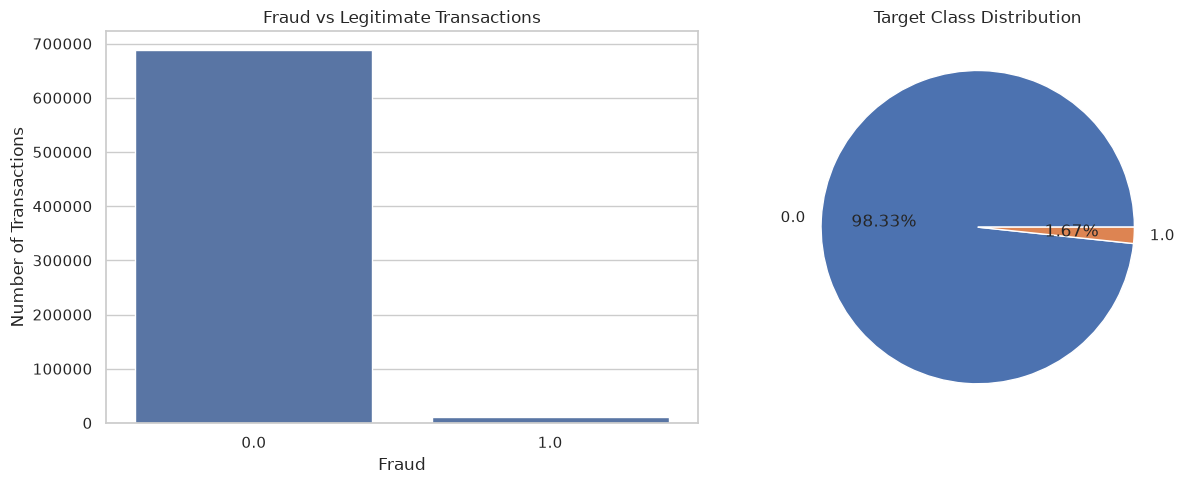

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(
    data=train,
    x="is_fraud",
    ax=axes[0]
)

axes[0].set_title("Fraud vs Legitimate Transactions")
axes[0].set_xlabel("Fraud")
axes[0].set_ylabel("Number of Transactions")

target_counts.plot(
    kind="pie",
    autopct="%1.2f%%",
    ax=axes[1]
)

axes[1].set_title("Target Class Distribution")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [6]:
fraud = (train["is_fraud"] == 1).sum()
legitimate = (train["is_fraud"] == 0).sum()

print("Fraud transactions:", fraud)
print("Legitimate transactions:", legitimate)
print("Imbalance ratio:", round(legitimate / fraud, 2))

Fraud transactions: 11689
Legitimate transactions: 688271
Imbalance ratio: 58.88


#### Fraud Pattern analysis

In [7]:
cat_cols = train.select_dtypes(include="object").columns.tolist()
print(cat_cols)

for col in cat_cols:
    rates = train.groupby(col)[TARGET].mean().sort_values(ascending=False)

    print(f"\nFraud rate by {col}:")
    display(rates.head(15))

['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']

Fraud rate by merchant_category:


/tmp/ipykernel_5359/296614264.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = train.select_dtypes(include="object").columns.tolist()


merchant_category
Gift Cards         0.072970
Crypto Exchange    0.065279
Gaming             0.055121
Electronics        0.030826
Streaming          0.022481
Travel             0.018597
Utilities          0.013824
Healthcare         0.012873
Fuel               0.012375
Restaurants        0.011434
Groceries          0.011117
Online Retail      0.011083
Name: is_fraud, dtype: float64


Fraud rate by card_type:


card_type
Amex          0.019019
Visa          0.016985
RuPay         0.016806
Mastercard    0.016025
Discover      0.014563
Name: is_fraud, dtype: float64


Fraud rate by auth_method:


auth_method
No Authentication    0.064450
3D Secure            0.014750
OTP                  0.014066
PIN                  0.008681
Biometric            0.004996
Name: is_fraud, dtype: float64


Fraud rate by channel:


channel
Online         0.017424
POS            0.016603
In-App         0.016329
ATM            0.015884
Contactless    0.015537
Name: is_fraud, dtype: float64


Fraud rate by device_type:


device_type
POS Terminal     0.017291
iPhone           0.017220
Mac              0.017102
Tablet           0.017011
Smart Watch      0.017009
ATM Machine      0.016956
Windows PC       0.016137
Android Phone    0.016104
Name: is_fraud, dtype: float64

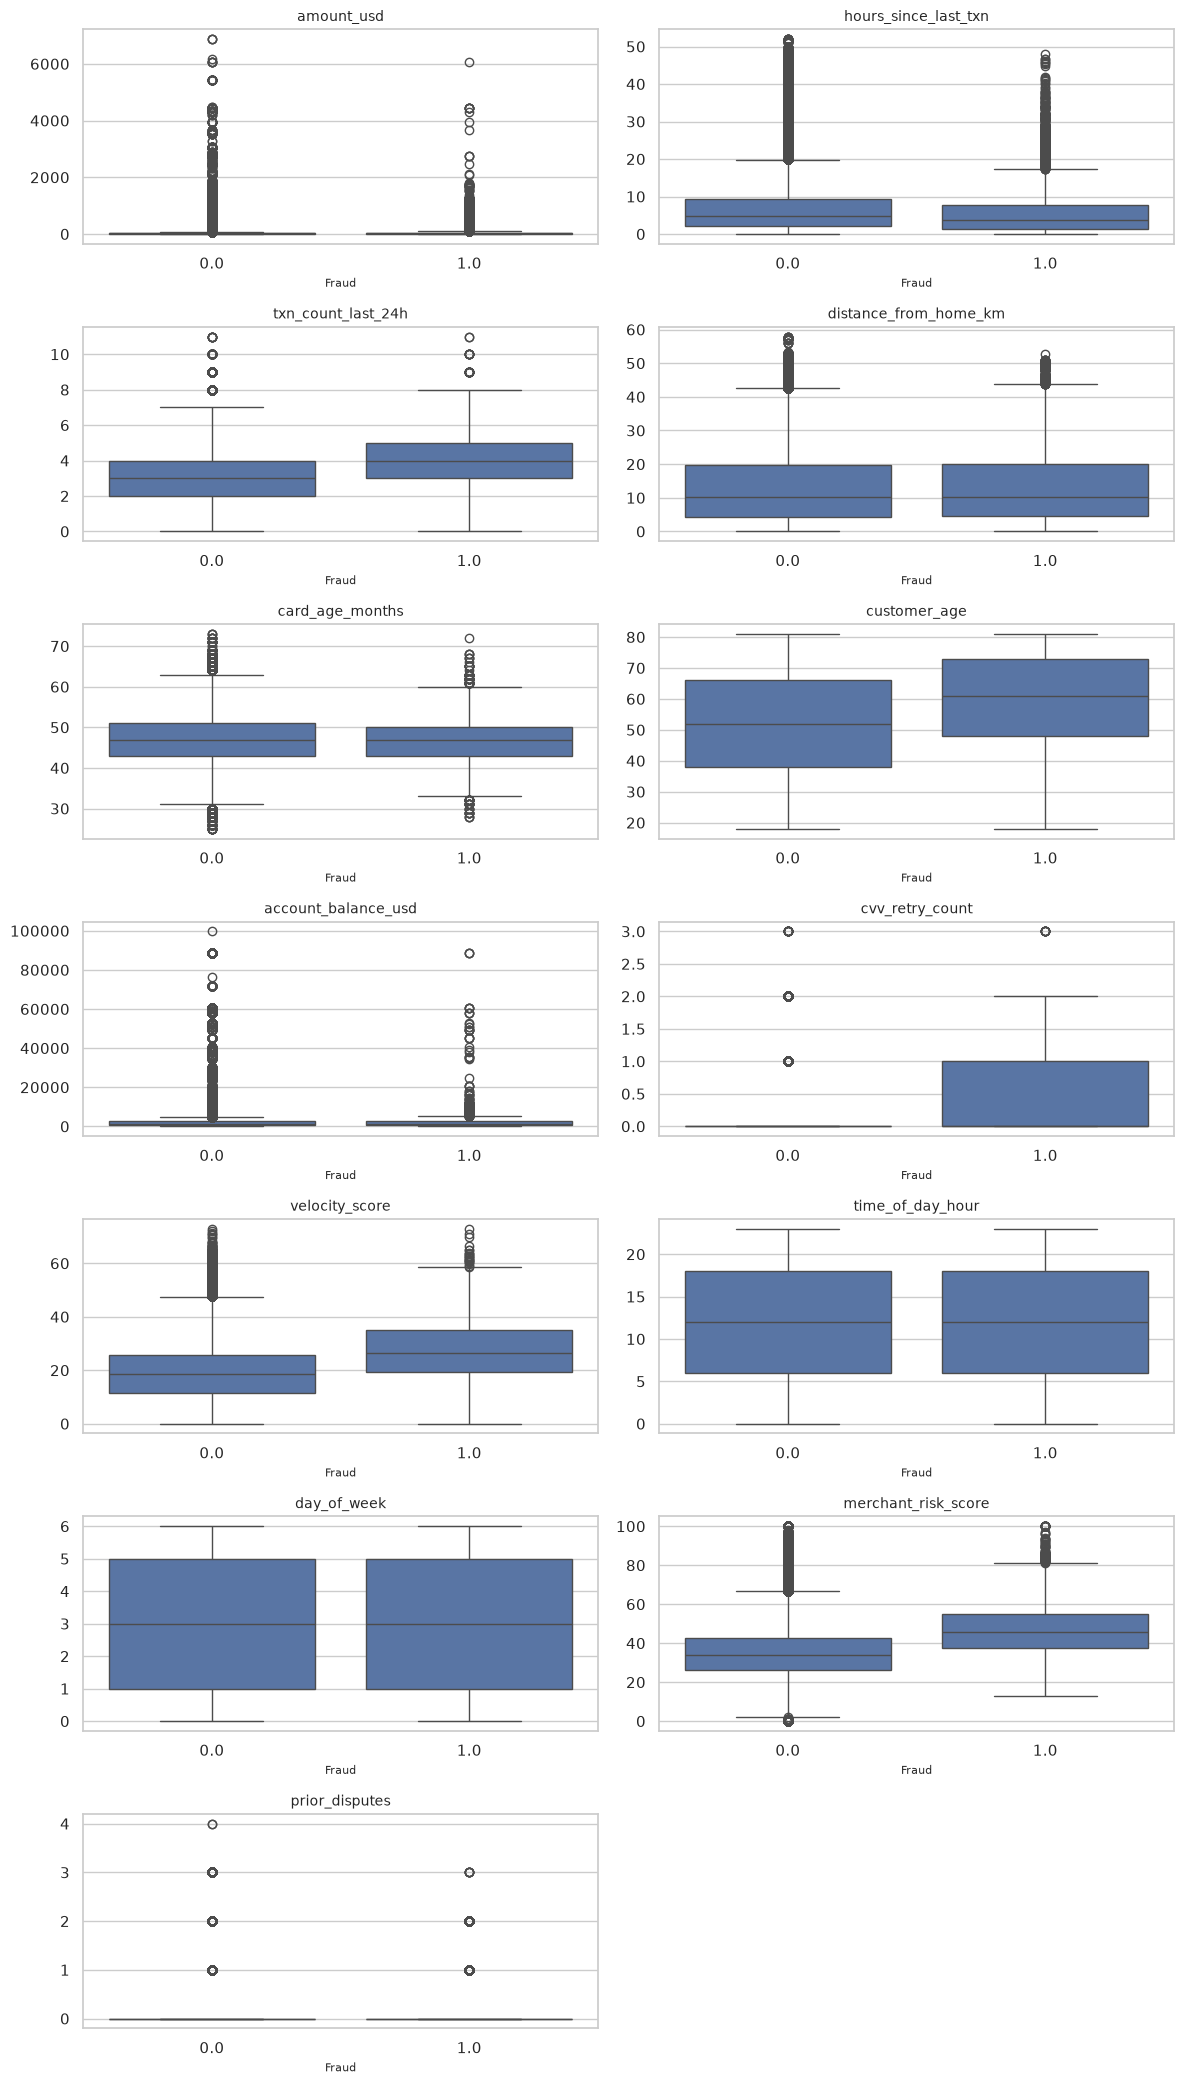

In [8]:
num_cols = train.select_dtypes(include=np.number).columns.drop(
    [TARGET, ID_COL], errors="ignore"
)

fig, axes = plt.subplots(
    (len(num_cols) + 1) // 2, 2,
    figsize=(12, 3 * ((len(num_cols) + 1) // 2))
)

axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    sns.boxplot(data=train, x=TARGET, y=col, ax=ax)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("Fraud", fontsize=8)
    ax.set_ylabel("")

for ax in axes[len(num_cols):]:
    ax.remove()

plt.tight_layout()
plt.show()

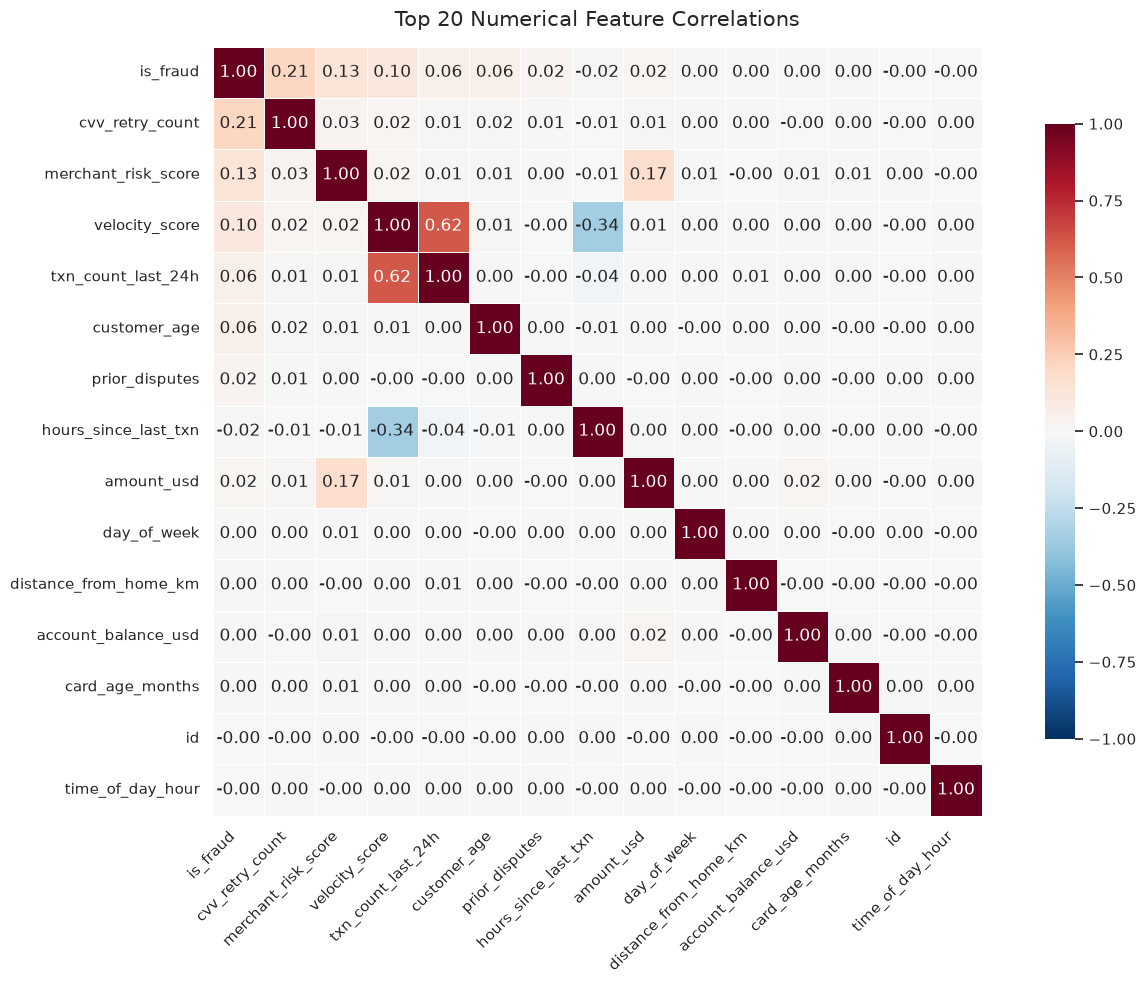

In [9]:
# Select numerical features
corr = train.select_dtypes(include=np.number).corr()

# Sort features by correlation with target
target_corr = corr[TARGET].abs().sort_values(ascending=False)
selected_cols = target_corr.index[:20]

corr = corr.loc[selected_cols, selected_cols]

# Plot
plt.figure(figsize=(14, 10))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={"shrink": 0.8}
)

plt.title("Top 20 Numerical Feature Correlations", fontsize=15, pad=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()